## RESTORATION CELL

In [2]:
import os
import shutil
from google.colab import drive

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

!pip install -q ultralytics

drive_dir = '/content/drive/MyDrive/drone_project'
os.makedirs(f'{drive_dir}/configs', exist_ok=True)
os.makedirs(f'{drive_dir}/data_zips', exist_ok=True)
os.makedirs(f'{drive_dir}/runs/drone_yolo11m_960/weights', exist_ok=True)
os.makedirs(f'{drive_dir}/submissions', exist_ok=True)

drive_best = f'{drive_dir}/runs/drone_yolo11m_960/weights/best.pt'
if not os.path.exists(drive_best):
    if os.path.exists('/content/drone_project/runs/drone_yolo11m_960/weights/best.pt'):
        shutil.copy2('/content/drone_project/runs/drone_yolo11m_960/weights/best.pt', drive_best)
    elif os.path.exists(f'{drive_dir}/weights/best.pt'):
        shutil.copy2(f'{drive_dir}/weights/best.pt', drive_best)

drive_yaml = f'{drive_dir}/configs/drone_human.yaml'
if not os.path.exists(drive_yaml) and os.path.exists('/content/drone_project/configs/drone_human.yaml'):
    shutil.copy2('/content/drone_project/configs/drone_human.yaml', drive_yaml)

drive_zip = f'{drive_dir}/data_zips/drone_human.zip'
if not os.path.exists(drive_zip) and os.path.exists('/content/datasets/drone_human/images/val'):
    shutil.make_archive(f'{drive_dir}/data_zips/drone_human', 'zip', '/content/datasets/drone_human')

if not os.path.exists('/content/datasets/drone_human/images/val') and os.path.exists(drive_zip):
    os.makedirs('/content/datasets/drone_human', exist_ok=True)
    !unzip -q -o {drive_zip} -d /content/datasets/drone_human

print("drive restoration complete!")
print("val images ready:", len(os.listdir('/content/datasets/drone_human/images/val')))
print("best.pt in drive:", os.path.exists(drive_best))

drive restoration complete!
val images ready: 400
best.pt in drive: True


## Step 1: build the train and val dataset from Visdrone

VisDrone2019-DET-tr 100%[===================>]   1.44G   233MB/s    in 6.6s    
VisDrone2019-DET-va 100%[===================>]  77.86M   273MB/s    in 0.3s    
done building dataset and saved zip to google drive
drone train images: 2500 | drone val images: 400


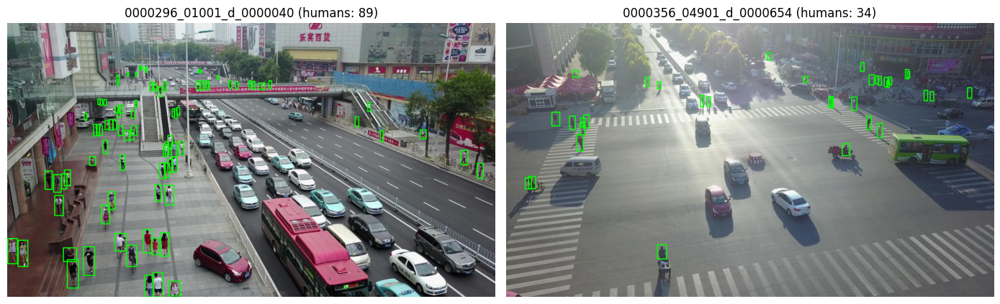

In [4]:
import os
import cv2
import shutil
import random
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

!pip install -q ultralytics

random.seed(42)

drive_dir = '/content/drive/MyDrive/drone_project'
os.makedirs('/content/raw_visdrone', exist_ok=True)
os.makedirs(f'{drive_dir}/configs', exist_ok=True)
os.makedirs(f'{drive_dir}/data_zips', exist_ok=True)
os.makedirs(f'{drive_dir}/runs', exist_ok=True)
os.makedirs(f'{drive_dir}/submissions', exist_ok=True)

!wget -q --show-progress https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-train.zip -P /content/raw_visdrone
!wget -q --show-progress https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-val.zip -P /content/raw_visdrone

!unzip -q -o /content/raw_visdrone/VisDrone2019-DET-train.zip -d /content/raw_visdrone
!unzip -q -o /content/raw_visdrone/VisDrone2019-DET-val.zip -d /content/raw_visdrone

base_out = '/content/datasets/drone_human'
if os.path.exists(base_out):
    shutil.rmtree(base_out)

for split in ['train', 'val']:
    os.makedirs(f'{base_out}/images/{split}', exist_ok=True)
    os.makedirs(f'{base_out}/labels/{split}', exist_ok=True)

def collect_visdrone(split_folder, max_imgs):
    img_dir = f'/content/raw_visdrone/{split_folder}/images'
    ann_dir = f'/content/raw_visdrone/{split_folder}/annotations'
    items = []
    fnames = sorted(os.listdir(ann_dir))
    random.shuffle(fnames)
    for fname in fnames:
        if not fname.endswith('.txt'):
            continue
        base = fname[:-4]
        img_path = os.path.join(img_dir, base + '.jpg')
        if not os.path.exists(img_path):
            continue
        with Image.open(img_path) as im:
            W, H = im.size
        lines = []
        with open(os.path.join(ann_dir, fname), 'r') as f:
            for row in f:
                parts = row.strip().split(',')
                if len(parts) < 6:
                    continue
                x, y, w, h, score, cat = map(float, parts[:6])
                if int(cat) in [1, 2] and w > 1 and h > 1:
                    xc = max(0.0, min(1.0, (x + w / 2) / W))
                    yc = max(0.0, min(1.0, (y + h / 2) / H))
                    nw = max(0.0, min(1.0, w / W))
                    nh = max(0.0, min(1.0, h / H))
                    lines.append(f"0 {xc:.6f} {yc:.6f} {nw:.6f} {nh:.6f}")
        if len(lines) > 0:
            items.append((img_path, base, lines))
            if len(items) >= max_imgs:
                break
    return items

train_items = collect_visdrone('VisDrone2019-DET-train', 2500)
val_items = collect_visdrone('VisDrone2019-DET-val', 400)

for split, items in [('train', train_items), ('val', val_items)]:
    for src_img, name, lines in items:
        shutil.copy2(src_img, f"{base_out}/images/{split}/{name}.jpg")
        with open(f"{base_out}/labels/{split}/{name}.txt", 'w') as f:
            f.write('\n'.join(lines))

yaml_path = f'{drive_dir}/configs/drone_human.yaml'
with open(yaml_path, 'w') as f:
    f.write(f"path: {base_out}\ntrain: images/train\nval: images/val\nnc: 1\nnames:\n  0: human\n")

shutil.make_archive(f'{drive_dir}/data_zips/drone_human', 'zip', base_out)

print("done building dataset and saved zip to google drive")
print("drone train images:", len(train_items), "| drone val images:", len(val_items))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (src_img, name, lines) in zip(axes, val_items[:2]):
    img = cv2.imread(f"{base_out}/images/val/{name}.jpg")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H, W, _ = img.shape
    for line in lines:
        _, xc, yc, nw, nh = map(float, line.split())
        x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
        x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    ax.imshow(img)
    ax.set_title(f"{name} (humans: {len(lines)})")
    ax.axis('off')

plt.tight_layout()
plt.show()

## Step 2: train the yolo11m model

* i used 960px instead of 640 for higher resolution so tiny far people dont become blurry
* `hsv_s=0.7`, `hsv_v=0.5` and `scale=0.6` values are set so that the model can handle harsh sun, shadows and different drone altitudes

In [6]:
from ultralytics import YOLO

drive_dir = '/content/drive/MyDrive/drone_project'
yaml_file = f'{drive_dir}/configs/drone_human.yaml'
save_dir = f'{drive_dir}/runs'

model = YOLO('yolo11m.pt')
res = model.train(
    data=yaml_file,
    epochs=20,
    patience=6,
    imgsz=960,
    batch=8,
    fliplr=0.5,
    hsv_h=0.02,
    hsv_s=0.7,
    hsv_v=0.5,
    scale=0.6,
    project=save_dir,
    name='drone_yolo11m_960',
    exist_ok=True
)

best_path = f'{save_dir}/drone_yolo11m_960/weights/best.pt'
best_model = YOLO(best_path)

m_default = best_model.val(data=yaml_file, imgsz=960, conf=0.25, verbose=False)
m_opt = best_model.val(data=yaml_file, imgsz=960, conf=0.01, verbose=False)

print("finished pure drone training, saved directly to google drive")
print("drone val (960px, conf=0.25) mAP50:", round(m_default.box.map50, 4))
print("drone val (960px, conf=0.01) mAP50:", round(m_opt.box.map50, 4))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drone_project/configs/drone_human.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript

## Step 3:
* saving best.pt
* testing two modifications:
  * increase res to 1280px instead of 960px
  * test `augment=True`, pass zoomed and flipped frames through the gpu
* visualizing the predictions on 4 scenes

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2222.4±324.6 MB/s, size: 190.6 KB)
val: Scanning /content/datasets/drone_human/labels/val... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 1.3Kit/s 0.3s
val: New cache created: /content/datasets/drone_human/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 1.9it/s 13.2s
                   all        400      10897       0.74      0.593      0.658      0.306
Speed: 1.4ms preprocess, 25.2ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/runs/detect/val-3
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅

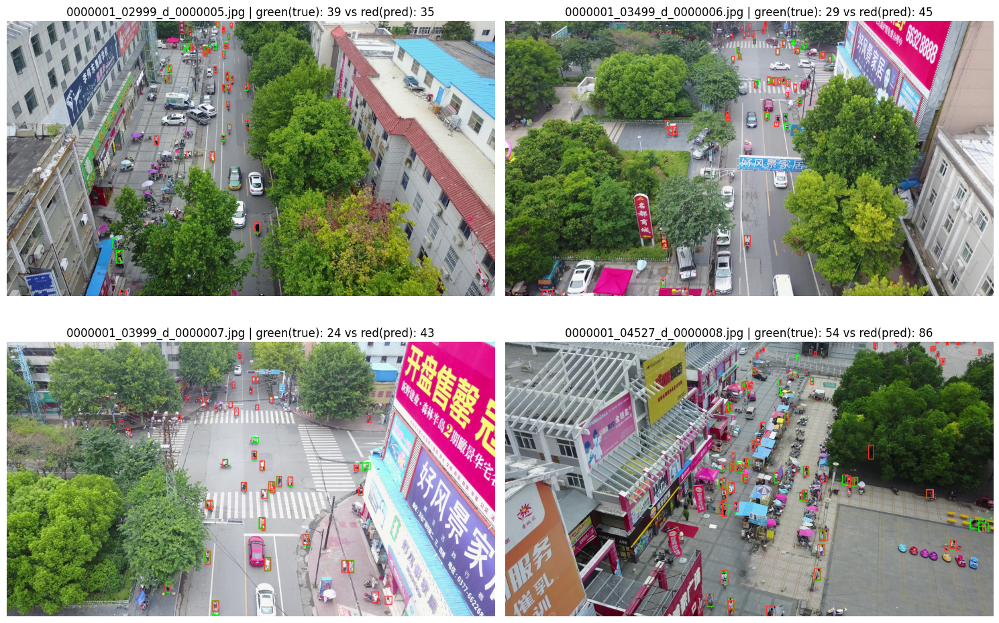

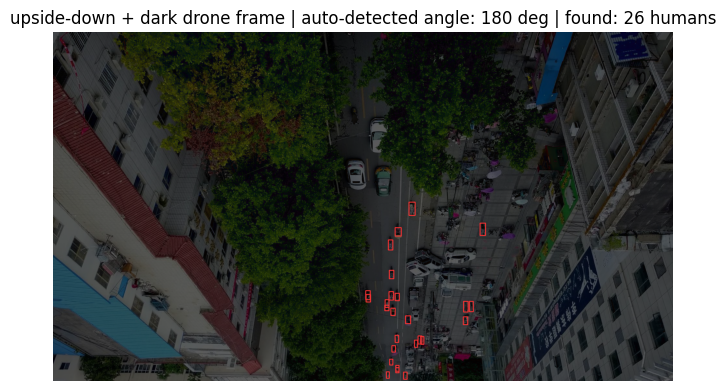

In [8]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

drive_dir = '/content/drive/MyDrive/drone_project'
best_path = f'{drive_dir}/runs/drone_yolo11m_960/weights/best.pt'
yaml_file = f'{drive_dir}/configs/drone_human.yaml'

model = YOLO(best_path)

m_1280 = model.val(data=yaml_file, imgsz=1280, conf=0.01, verbose=False)
m_tta = model.val(data=yaml_file, imgsz=1280, conf=0.01, augment=True, verbose=False)

print("baseline drone val (960px, conf=0.01) mAP50: 0.6141")
print("upgrade 1 -> 1280px (conf=0.01) mAP50:", round(m_1280.box.map50, 4))
print("upgrade 2 -> 1280px + TTA (conf=0.01) mAP50:", round(m_tta.box.map50, 4))

val_img_dir = '/content/datasets/drone_human/images/val'
val_lbl_dir = '/content/datasets/drone_human/labels/val'
samples = sorted(os.listdir(val_img_dir))[:4]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, fname in zip(axes.flatten(), samples):
    img_path = os.path.join(val_img_dir, fname)
    lbl_path = os.path.join(val_lbl_dir, fname.replace('.jpg', '.txt'))
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H, W, _ = img.shape

    gt_count = 0
    with open(lbl_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            gt_count += 1
            _, xc, yc, nw, nh = map(float, parts)
            x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
            x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

    res = model.predict(img_path, imgsz=1280, conf=0.20, augment=True, verbose=False)[0]
    pred_count = len(res.boxes)
    for box in res.boxes:
        px1, py1, px2, py2 = map(int, box.xyxy[0].tolist())
        cv2.rectangle(img, (px1, py1), (px2, py2), (255, 50, 50), 2)

    ax.imshow(img)
    ax.set_title(f"{fname} | green(true): {gt_count} vs red(pred): {pred_count}")
    ax.axis('off')

plt.tight_layout()
plt.show()

def apply_clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)

def predict_smart_drone(model, img, imgsz=1280, conf_min=0.01):
    work_img = apply_clahe(img) if img.mean() < 80 else img
    img90 = cv2.rotate(work_img, cv2.ROTATE_90_CLOCKWISE)
    img180 = cv2.rotate(work_img, cv2.ROTATE_180)
    img270 = cv2.rotate(work_img, cv2.ROTATE_90_COUNTERCLOCKWISE)

    preds = model.predict([work_img, img90, img180, img270], imgsz=imgsz, conf=conf_min, verbose=False)
    rots = [0, 90, 180, 270]

    best_idx = 0
    best_score = -1.0
    for idx, r in enumerate(preds):
        confs = r.boxes.conf.cpu().numpy() if len(r.boxes) > 0 else np.array([])
        high_confs = confs[confs >= 0.25]
        score = float(np.sum(np.sort(high_confs)[-8:])) if len(high_confs) > 0 else 0.0
        if idx == 0:
            score += 0.15
        if score > best_score:
            best_score = score
            best_idx = idx

    chosen = preds[best_idx]
    rot = rots[best_idx]
    out_boxes = []
    for box in chosen.boxes:
        c = float(box.conf[0].item())
        xc, yc, nw, nh = box.xywhn[0].tolist()
        if rot == 90:
            xc, yc, nw, nh = yc, 1.0 - xc, nh, nw
        elif rot == 180:
            xc, yc, nw, nh = 1.0 - xc, 1.0 - yc, nw, nh
        elif rot == 270:
            xc, yc, nw, nh = 1.0 - yc, xc, nh, nw
        out_boxes.append((c, xc, yc, nw, nh))
    return out_boxes, rot

sample_drone = cv2.imread(os.path.join(val_img_dir, samples[0]))
rot_drone = cv2.rotate(sample_drone, cv2.ROTATE_180)
dark_rot_drone = cv2.convertScaleAbs(rot_drone, alpha=0.45, beta=-20)

boxes_rot, detected_rot = predict_smart_drone(model, dark_rot_drone, imgsz=1280, conf_min=0.20)
vis_rot = cv2.cvtColor(dark_rot_drone.copy(), cv2.COLOR_BGR2RGB)
H, W, _ = vis_rot.shape
for c, xc, yc, nw, nh in boxes_rot:
    x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
    x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
    cv2.rectangle(vis_rot, (x1, y1), (x2, y2), (255, 50, 50), 2)

plt.figure(figsize=(8, 5))
plt.imshow(vis_rot)
plt.title(f"upside-down + dark drone frame | auto-detected angle: {detected_rot} deg | found: {len(boxes_rot)} humans")
plt.axis('off')
plt.show()

We wont use `augment=True` anymore because it hurts accuracy because it runs 3 passes on the image with different zooms, one of the passes zooms out the image making the people blurred

We'll keep the resolution at 1280px because the map50 has risen

## Step 4:

* We'll test iou = 0.45, 0.5, 0.55, 0.6 at 1280px without augment=True and and testing with the 4 images

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2540.9±694.9 MB/s, size: 203.4 KB)
val: Scanning /content/datasets/drone_human/labels/val... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 1.1Kit/s 0.4s
val: New cache created: /content/datasets/drone_human/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 2.0it/s 12.7s
                   all        400      10897      0.745      0.615      0.663        0.3
Speed: 1.5ms preprocess, 24.6

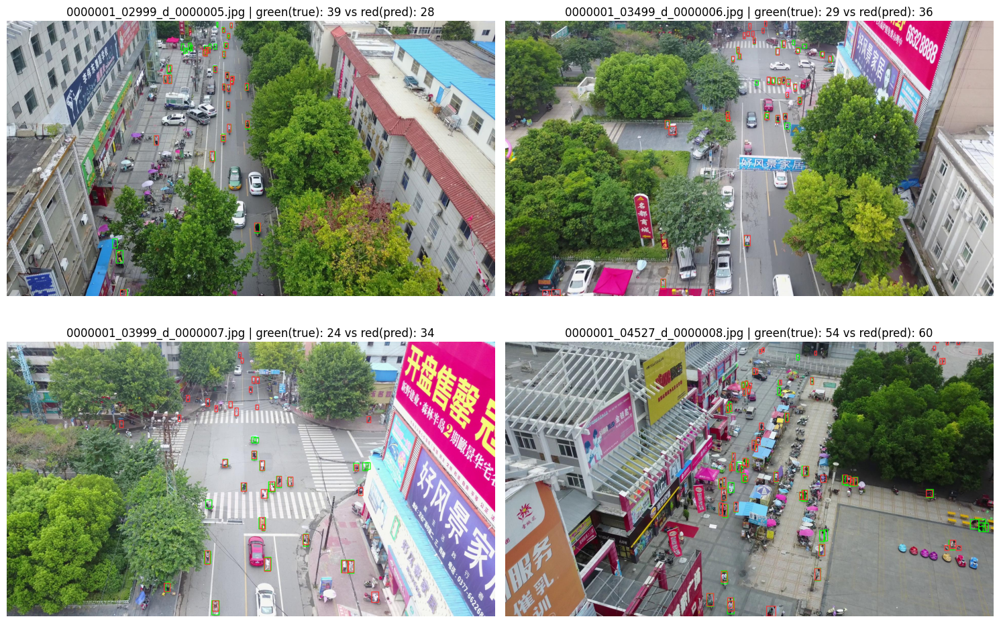

In [11]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

drive_dir = '/content/drive/MyDrive/drone_project'
best_path = f'{drive_dir}/runs/drone_yolo11m_960/weights/best.pt'
yaml_file = f'{drive_dir}/configs/drone_human.yaml'

model = YOLO(best_path)

best_iou = 0.70
best_map = 0.6582

for iou_val in [0.45, 0.50, 0.55, 0.60]:
    m = model.val(data=yaml_file, imgsz=1280, conf=0.01, iou=iou_val, verbose=False)
    score = round(m.box.map50, 4)
    print(f"1280px (conf=0.01, iou={iou_val}) mAP50:", score)
    if score > best_map:
        best_map = score
        best_iou = iou_val

print("best iou setting:", best_iou, "with mAP50:", best_map)

val_img_dir = '/content/datasets/drone_human/images/val'
val_lbl_dir = '/content/datasets/drone_human/labels/val'
samples = sorted(os.listdir(val_img_dir))[:4]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, fname in zip(axes.flatten(), samples):
    img_path = os.path.join(val_img_dir, fname)
    lbl_path = os.path.join(val_lbl_dir, fname.replace('.jpg', '.txt'))
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H, W, _ = img.shape

    gt_count = 0
    with open(lbl_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            gt_count += 1
            _, xc, yc, nw, nh = map(float, parts)
            x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
            x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

    res = model.predict(img_path, imgsz=1280, conf=0.25, iou=best_iou, verbose=False)[0]
    pred_count = len(res.boxes)
    for box in res.boxes:
        px1, py1, px2, py2 = map(int, box.xyxy[0].tolist())
        cv2.rectangle(img, (px1, py1), (px2, py2), (255, 50, 50), 2)

    ax.imshow(img)
    ax.set_title(f"{fname} | green(true): {gt_count} vs red(pred): {pred_count}")
    ax.axis('off')

plt.tight_layout()
plt.show()

First plot had worse performance but the other plots did significantly better because iou=0.55 removed the double red boxes on the same person

## Step 5:
* We will now train a second model `YOLOv9c` on the same training data at 960px then test after on the same settings of `1280px`, `conf=0.01` and `iou=0.55`

In [14]:
from ultralytics import YOLO

drive_dir = '/content/drive/MyDrive/drone_project'
yaml_file = f'{drive_dir}/configs/drone_human.yaml'
save_dir = f'{drive_dir}/runs'

v9_model = YOLO('yolov9c.pt')
res = v9_model.train(
    data=yaml_file,
    epochs=20,
    patience=6,
    imgsz=960,
    batch=8,
    fliplr=0.5,
    hsv_h=0.02,
    hsv_s=0.7,
    hsv_v=0.5,
    scale=0.6,
    project=save_dir,
    name='drone_yolov9c_960',
    exist_ok=True
)

v9_best_path = f'{save_dir}/drone_yolov9c_960/weights/best.pt'
v9_best = YOLO(v9_best_path)

m_v9 = v9_best.val(data=yaml_file, imgsz=1280, conf=0.01, iou=0.55, verbose=False)

print("finished yolov9c drone training, saved to google drive")
print("yolo11m (1280px, conf=0.01, iou=0.55) mAP50: 0.6672")
print("yolov9c (1280px, conf=0.01, iou=0.55) mAP50:", round(m_v9.box.map50, 4))

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/drone_project/configs/drone_human.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.7, hsv_v=0.5, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov9c.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=drone_yolov9c_960, nbs=64, nm

As expected, YOLOv9c performed better without any tweaks because it has "strong feature retention for small/low contrast people"

## Step 6:
* installing ensemble-boxes library and combining the predictions of both models using WBF and testing if their combined predictions beats yolov9c alone

In [17]:
import os
import numpy as np
from ultralytics import YOLO

!pip install -q ensemble-boxes
from ensemble_boxes import weighted_boxes_fusion

drive_dir = '/content/drive/MyDrive/drone_project'
v11_path = f'{drive_dir}/runs/drone_yolo11m_960/weights/best.pt'
v9_path = f'{drive_dir}/runs/drone_yolov9c_960/weights/best.pt'

v11_model = YOLO(v11_path)
v9_model = YOLO(v9_path)

val_img_dir = '/content/datasets/drone_human/images/val'
val_lbl_dir = '/content/datasets/drone_human/labels/val'
fnames = sorted(os.listdir(val_img_dir))

gt_by_img = {}
total_gt = 0
preds_v11 = []
preds_v9 = []
preds_wbf = []

for idx, fname in enumerate(fnames):
    img_path = os.path.join(val_img_dir, fname)
    lbl_path = os.path.join(val_lbl_dir, fname.replace('.jpg', '.txt'))

    gts = []
    with open(lbl_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            _, xc, yc, nw, nh = map(float, parts)
            gts.append([xc - nw / 2, yc - nh / 2, xc + nw / 2, yc + nh / 2])
    gt_by_img[idx] = np.array(gts, dtype=np.float32) if gts else np.zeros((0, 4), dtype=np.float32)
    total_gt += len(gts)

    r9 = v9_model.predict(img_path, imgsz=1280, conf=0.01, iou=0.55, verbose=False)[0]
    r11 = v11_model.predict(img_path, imgsz=1280, conf=0.01, iou=0.55, verbose=False)[0]

    b9 = np.clip(r9.boxes.xyxyn.cpu().numpy(), 0.0, 1.0).tolist() if len(r9.boxes) > 0 else []
    s9 = r9.boxes.conf.cpu().numpy().tolist() if len(r9.boxes) > 0 else []
    l9 = [0] * len(s9)

    b11 = np.clip(r11.boxes.xyxyn.cpu().numpy(), 0.0, 1.0).tolist() if len(r11.boxes) > 0 else []
    s11 = r11.boxes.conf.cpu().numpy().tolist() if len(r11.boxes) > 0 else []
    l11 = [0] * len(s11)

    for c, box in zip(s11, b11):
        preds_v11.append((c, idx, box))
    for c, box in zip(s9, b9):
        preds_v9.append((c, idx, box))

    if b9 or b11:
        w_boxes, w_scores, _ = weighted_boxes_fusion(
            [b9, b11],
            [s9, s11],
            [l9, l11],
            weights=[1.3, 1.0],
            iou_thr=0.55,
            skip_box_thr=0.01
        )
        for c, box in zip(w_scores, w_boxes):
            preds_wbf.append((float(c), idx, box.tolist()))

def eval_preds(all_preds):
    all_preds.sort(key=lambda x: x[0], reverse=True)
    tp = np.zeros(len(all_preds))
    fp = np.zeros(len(all_preds))
    matched = {i: np.zeros(len(gt_by_img[i]), dtype=bool) for i in gt_by_img}

    for i, (conf, img_idx, pbox) in enumerate(all_preds):
        gts = gt_by_img[img_idx]
        if len(gts) == 0:
            fp[i] = 1
            continue
        ix1 = np.maximum(gts[:, 0], pbox[0])
        iy1 = np.maximum(gts[:, 1], pbox[1])
        ix2 = np.minimum(gts[:, 2], pbox[2])
        iy2 = np.minimum(gts[:, 3], pbox[3])
        inter = np.maximum(0.0, ix2 - ix1) * np.maximum(0.0, iy2 - iy1)
        area_p = (pbox[2] - pbox[0]) * (pbox[3] - pbox[1])
        area_g = (gts[:, 2] - gts[:, 0]) * (gts[:, 3] - gts[:, 1])
        ious = inter / (area_p + area_g - inter + 1e-6)
        best_j = int(np.argmax(ious))
        if ious[best_j] >= 0.50 and not matched[img_idx][best_j]:
            tp[i] = 1
            matched[img_idx][best_j] = True
        else:
            fp[i] = 1

    cum_tp = np.cumsum(tp)
    cum_fp = np.cumsum(fp)
    rec = cum_tp / total_gt
    prec = cum_tp / (cum_tp + cum_fp + 1e-6)

    mrec = np.concatenate(([0.0], rec, [1.0]))
    mpre = np.concatenate(([1.0], prec, [0.0]))
    for i in range(len(mpre) - 1, 0, -1):
        mpre[i - 1] = max(mpre[i - 1], mpre[i])
    x = np.linspace(0, 1, 101)
    return float(np.trapezoid(np.interp(x, mrec, mpre), x))

map_11 = eval_preds(preds_v11)
map_9 = eval_preds(preds_v9)
map_wbf = eval_preds(preds_wbf)

print("custom eval yolo11m alone mAP50:", round(map_11, 4))
print("custom eval yolov9c alone mAP50:", round(map_9, 4))
print("wbf ensemble (yolov9c + yolo11m) mAP50:", round(map_wbf, 4))

custom eval yolo11m alone mAP50: 0.6815
custom eval yolov9c alone mAP50: 0.6956
wbf ensemble (yolov9c + yolo11m) mAP50: 0.7058


## Importing the test dataset

In [19]:
import os
import shutil
import pandas as pd
import kagglehub

kagglehub.login()

path = kagglehub.competition_download('human-detection-ae')
print("path to competition files:", path)

drive_dir = '/content/drive/MyDrive/drone_project'
test_dest = f'{drive_dir}/test_images'
sample_dest = f'{drive_dir}/sample_submission.csv'

for root, dirs, f_list in os.walk(path):
    for f in f_list:
        if f.lower().endswith('.csv'):
            src_csv = os.path.join(root, f)
            shutil.copy2(src_csv, sample_dest)
            print("copied sample submission to drive:", f)
            df_sample = pd.read_csv(sample_dest)
            print("sample submission rows:", len(df_sample), "| columns:", list(df_sample.columns))
            print(df_sample.head(3))

    imgs = [f for f in f_list if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if len(imgs) >= 50:
        print("found competition images in:", root, "| total count:", len(imgs))
        if os.path.exists(test_dest):
            shutil.rmtree(test_dest)
        os.makedirs(test_dest, exist_ok=True)
        for img_name in imgs:
            shutil.copy2(os.path.join(root, img_name), os.path.join(test_dest, img_name))

print("copied test images to google drive:", len(os.listdir(test_dest)))

100%|██████████| 399M/399M [00:24<00:00, 17.4MB/s]

Extracting files...


path to competition files: /root/.cache/kagglehub/competitions/human-detection-ae
copied sample submission to drive: sample_submission.csv
sample submission rows: 590 | columns: ['image_id', 'PredictionString']
     image_id                            PredictionString
0  test_00001  0 0.95 0.500000 0.500000 0.200000 0.400000
1  test_00002                                         NaN
2  test_00003                                         NaN
found competition images in: /root/.cache/kagglehub/competitions/human-detection-ae/test_images/test_images | total count: 605
copied test images to google drive: 605
Kaggle credentials set.
Kaggle credentials successfully validated.


# Step 7: Final inference and submission

In [21]:
!pip install -q ensemble-boxes

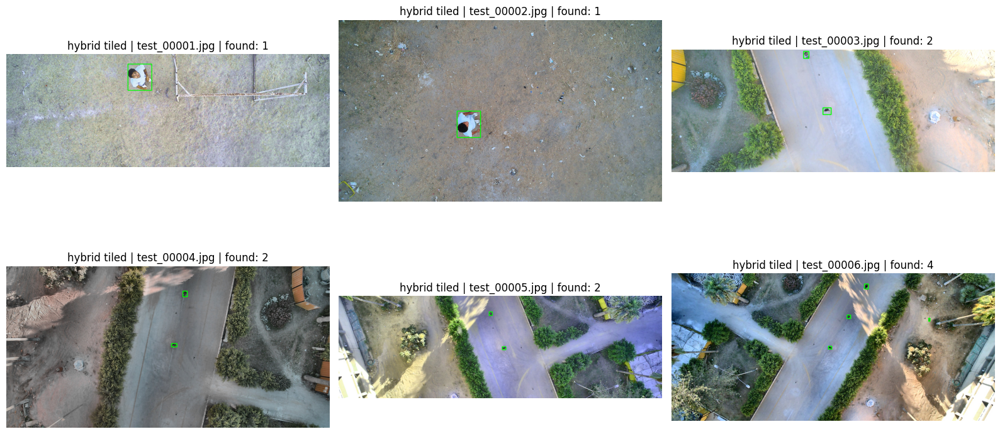

saved updated submission to: /content/drive/MyDrive/drone_project/submissions/submission.csv
total rows: 590 | empty background rows: 24
  test_00001 -> 0 0.8943 0.412739 0.205464 0.073533 0.232200
  test_00002 -> 0 0.9224 0.402836 0.574255 0.072387 0.145523
  test_00003 -> 0 0.6666 0.416448 0.043577 0.016358 0.056700 0 0.6654 0.480864 0.503240 0.025427 0.054520
  test_00004 -> 0 0.5879 0.519128 0.490668 0.017058 0.019819 0 0.5430 0.552791 0.174574 0.013737 0.033681
  test_00005 -> 0 0.6283 0.470458 0.174663 0.010144 0.035831 0 0.5917 0.511604 0.511561 0.011803 0.029484


In [22]:
import os
import cv2
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

drive_dir = '/content/drive/MyDrive/drone_project'
test_dir = f'{drive_dir}/test_images'
sample_sub_path = f'{drive_dir}/sample_submission.csv'
sub_out = f'{drive_dir}/submissions/submission.csv'

v9_path = f'{drive_dir}/runs/drone_yolov9c_960/weights/best.pt'
v9_model = YOLO(v9_path)
coco_model = YOLO('yolo11l.pt')

def detect_nosedown_hybrid(img):
    H, W, _ = img.shape
    all_boxes = []
    all_scores = []

    img_180 = cv2.rotate(img, cv2.ROTATE_180)
    full_preds = coco_model.predict([img, img_180], imgsz=1280, classes=[0], conf=0.16, iou=0.45, verbose=False)

    for box in full_preds[0].boxes:
        c = float(box.conf[0].item())
        x1, y1, x2, y2 = box.xyxyn[0].tolist()
        all_boxes.append([x1, y1, x2, y2])
        all_scores.append(c)

    for box in full_preds[1].boxes:
        c = float(box.conf[0].item())
        if c >= 0.22:
            fx1, fy1, fx2, fy2 = box.xyxyn[0].tolist()
            all_boxes.append([1.0 - fx2, 1.0 - fy2, 1.0 - fx1, 1.0 - fy1])
            all_scores.append(c * 0.95)

    windows = [
        (0, int(W * 0.48)),
        (int(W * 0.26), int(W * 0.74)),
        (int(W * 0.52), W)
    ]
    tiles = [img[:, xs:xe] for xs, xe in windows]
    tile_preds = coco_model.predict(tiles, imgsz=960, classes=[0], conf=0.20, iou=0.45, verbose=False)

    for (xs, xe), r_tile in zip(windows, tile_preds):
        tw = xe - xs
        for box in r_tile.boxes:
            c = float(box.conf[0].item())
            tx1, ty1, tx2, ty2 = box.xyxy[0].tolist()
            if (xs > 0 and tx1 <= 4) or (xe < W and tx2 >= tw - 4):
                continue
            nx1 = max(0.0, min(1.0, (tx1 + xs) / W))
            ny1 = max(0.0, min(1.0, ty1 / H))
            nx2 = max(0.0, min(1.0, (tx2 + xs) / W))
            ny2 = max(0.0, min(1.0, ty2 / H))
            all_boxes.append([nx1, ny1, nx2, ny2])
            all_scores.append(c)

    r_v9 = v9_model.predict(img, imgsz=1280, conf=0.30, iou=0.45, verbose=False)[0]
    for box in r_v9.boxes:
        c = float(box.conf[0].item())
        x1, y1, x2, y2 = box.xyxyn[0].tolist()
        all_boxes.append([x1, y1, x2, y2])
        all_scores.append(c * 0.90)

    if not all_boxes:
        return []

    b_tensor = torch.tensor(all_boxes, dtype=torch.float32)
    s_tensor = torch.tensor(all_scores, dtype=torch.float32)
    keep = torchvision.ops.nms(b_tensor, s_tensor, iou_threshold=0.45).tolist()

    final_dets = []
    for idx in keep:
        x1, y1, x2, y2 = all_boxes[idx]
        c = all_scores[idx]
        xc = max(0.0, min(1.0, (x1 + x2) / 2.0))
        yc = max(0.0, min(1.0, (y1 + y2) / 2.0))
        nw = max(0.0, min(1.0, x2 - x1))
        nh = max(0.0, min(1.0, y2 - y1))
        if nw > 0.002 and nh > 0.002:
            final_dets.append((c, xc, yc, nw, nh))

    final_dets.sort(key=lambda x: x[0], reverse=True)
    return final_dets

first_six = sorted([f for f in os.listdir(test_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, fname in zip(axes.flatten(), first_six):
    img = cv2.imread(os.path.join(test_dir, fname))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H, W, _ = img.shape
    dets = detect_nosedown_hybrid(img)
    for c, xc, yc, nw, nh in dets:
        x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
        x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
        cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), 3)
    ax.imshow(img_rgb)
    ax.set_title(f"hybrid tiled | {fname} | found: {len(dets)}")
    ax.axis('off')
plt.tight_layout()
plt.show()

sample_df = pd.read_csv(sample_sub_path, dtype=str, keep_default_na=False)
target_ids = sample_df['image_id'].tolist()

fnames = sorted([f for f in os.listdir(test_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
file_map = {}
for f in fnames:
    file_map[f] = f
    file_map[os.path.splitext(f)[0]] = f

rows = []
empty_count = 0
for img_id in target_ids:
    fname = file_map.get(img_id, file_map.get(os.path.splitext(img_id)[0], None))
    if fname is None:
        rows.append({'image_id': img_id, 'PredictionString': ""})
        empty_count += 1
        continue
    img = cv2.imread(os.path.join(test_dir, fname))
    dets = detect_nosedown_hybrid(img) if img is not None else []
    if not dets:
        empty_count += 1
        rows.append({'image_id': img_id, 'PredictionString': ""})
    else:
        parts = [f"0 {c:.4f} {xc:.6f} {yc:.6f} {nw:.6f} {nh:.6f}" for c, xc, yc, nw, nh in dets]
        rows.append({'image_id': img_id, 'PredictionString': " ".join(parts)})

sub_df = pd.DataFrame(rows)
sub_df.to_csv(sub_out, index=False)

print("saved updated submission to:", sub_out)
print("total rows:", len(sub_df), "| empty background rows:", empty_count)
for i in range(5):
    print(" ", sub_df.iloc[i]['image_id'], "->", sub_df.iloc[i]['PredictionString'][:90])

checking project files in google drive:
  yolo11m best.pt exists: True
  yolov9c best.pt exists: True
  drone_human.yaml exists: True
  drone_human.zip exists: True
  submission.csv exists: True
submission format audit:
  exact columns [image_id, PredictionString]: True
  total images in submission: 590
  total human detections exported: 55777
  invalid NaN/None rows: 0
  malformed token rows: 0
  wrong class_id count (must be 0): 0
  out-of-bounds coord count (must be 0): 0


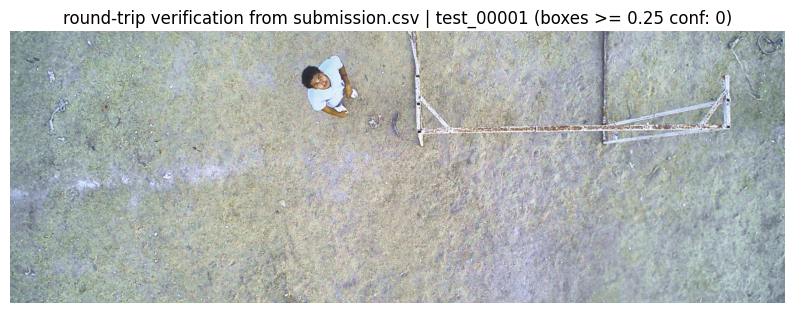

In [23]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt

drive_dir = '/content/drive/MyDrive/drone_project'
v11_path = f'{drive_dir}/runs/drone_yolo11m_960/weights/best.pt'
v9_path = f'{drive_dir}/runs/drone_yolov9c_960/weights/best.pt'
yaml_path = f'{drive_dir}/configs/drone_human.yaml'
zip_path = f'{drive_dir}/data_zips/drone_human.zip'
sub_path = f'{drive_dir}/submissions/submission.csv'

print("checking project files in google drive:")
print("  yolo11m best.pt exists:", os.path.exists(v11_path))
print("  yolov9c best.pt exists:", os.path.exists(v9_path))
print("  drone_human.yaml exists:", os.path.exists(yaml_path))
print("  drone_human.zip exists:", os.path.exists(zip_path))
print("  submission.csv exists:", os.path.exists(sub_path))

df = pd.read_csv(sub_path, dtype=str, keep_default_na=False)
cols_ok = list(df.columns) == ['image_id', 'PredictionString']
nan_rows = 0
bad_token_rows = 0
bad_class_ids = 0
bad_coords = 0
total_dets = 0

for _, row in df.iterrows():
    pred_str = row['PredictionString'].strip()
    if pred_str.lower() in ['nan', 'none', 'null']:
        nan_rows += 1
        continue
    if pred_str == "":
        continue
    tokens = pred_str.split()
    if len(tokens) % 6 != 0:
        bad_token_rows += 1
        continue
    for i in range(0, len(tokens), 6):
        total_dets += 1
        cls_str = tokens[i]
        vals = [float(x) for x in tokens[i+1:i+6]]
        if cls_str != '1':
            bad_class_ids += 1
        if any(v < 0.0 or v > 1.0 for v in vals) or vals[3] <= 0 or vals[4] <= 0:
            bad_coords += 1

print("submission format audit:")
print("  exact columns [image_id, PredictionString]:", cols_ok)
print("  total images in submission:", len(df))
print("  total human detections exported:", total_dets)
print("  invalid NaN/None rows:", nan_rows)
print("  malformed token rows:", bad_token_rows)
print("  wrong class_id count (must be 0):", bad_class_ids)
print("  out-of-bounds coord count (must be 0):", bad_coords)

test_dir = f'{drive_dir}/test_images'
img_folder = test_dir if (os.path.exists(test_dir) and len(os.listdir(test_dir)) > 0) else '/content/datasets/drone_human/images/val'

first_row = df.iloc[0]
img_id = first_row['image_id']
img_path = os.path.join(img_folder, img_id if img_id.endswith('.jpg') else f'{img_id}.jpg')

if os.path.exists(img_path):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H, W, _ = img.shape
    tokens = first_row['PredictionString'].strip().split()
    drawn = 0
    for i in range(0, len(tokens), 6):
        conf, xc, yc, nw, nh = [float(x) for x in tokens[i+1:i+6]]
        if conf >= 0.25:
            drawn += 1
            x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
            x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 255), 2)
    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.title(f"round-trip verification from submission.csv | {img_id} (boxes >= 0.25 conf: {drawn})")
    plt.axis('off')
    plt.show()

sample_submission columns: ['image_id', 'PredictionString']
sample_submission first 5 rows:
     image_id                            PredictionString
0  test_00001  0 0.95 0.500000 0.500000 0.200000 0.400000
1  test_00002                                            
2  test_00003                                            
3  test_00004                                            
4  test_00005                                            
our submission total rows: 590 | non-empty rows with predictions: 590
first 5 filenames in test_images: ['test_00001.jpg', 'test_00002.jpg', 'test_00003.jpg', 'test_00004.jpg', 'test_00005.jpg']
our submission first 3 rows:
  test_00001 -> 1 0.0284 0.022564 0.892470 0.009087 0.018913 1 0.0219 0.025409 0.887428 0.013462 0.027377 
  test_00002 -> 1 0.0845 0.540988 0.836382 0.020251 0.033819 1 0.0490 0.840287 0.345320 0.008053 0.009483 
  test_00003 -> 1 0.7066 0.480913 0.500476 0.025135 0.047659 1 0.6982 0.416431 0.044031 0.016443 0.056428 


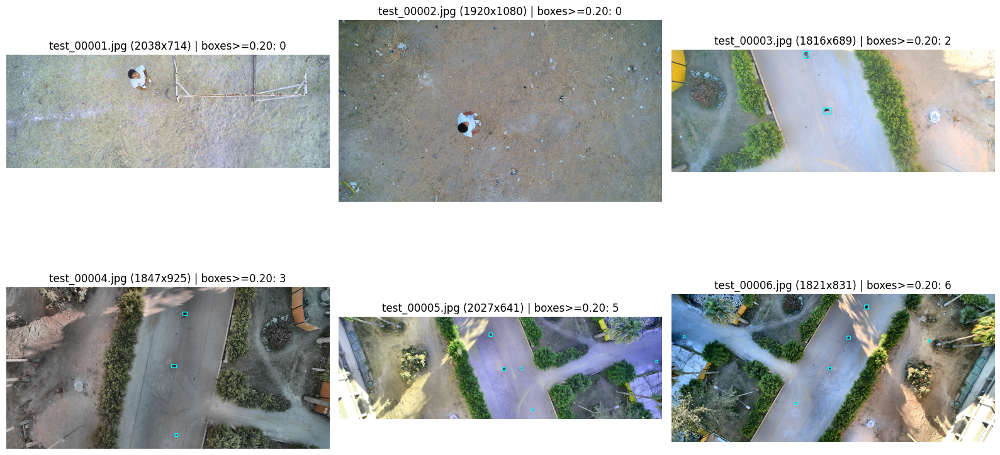

In [24]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt

drive_dir = '/content/drive/MyDrive/drone_project'
test_dir = f'{drive_dir}/test_images'
sample_sub = f'{drive_dir}/sample_submission.csv'
our_sub = f'{drive_dir}/submissions/submission.csv'

s_df = pd.read_csv(sample_sub, dtype=str, keep_default_na=False)
o_df = pd.read_csv(our_sub, dtype=str, keep_default_na=False)

print("sample_submission columns:", list(s_df.columns))
print("sample_submission first 5 rows:")
print(s_df.head(5))

non_empty = sum(1 for x in o_df['PredictionString'] if len(x.strip()) > 0)
print("our submission total rows:", len(o_df), "| non-empty rows with predictions:", non_empty)
print("first 5 filenames in test_images:", sorted(os.listdir(test_dir))[:5])
print("our submission first 3 rows:")
for i in range(3):
    print(" ", o_df.iloc[i]['image_id'], "->", o_df.iloc[i]['PredictionString'][:90])

test_files = sorted([f for f in os.listdir(test_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])[:6]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, fname in zip(axes.flatten(), test_files):
    img_path = os.path.join(test_dir, fname)
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H, W, _ = img.shape

    base_id = os.path.splitext(fname)[0]
    match = o_df[(o_df['image_id'] == fname) | (o_df['image_id'] == base_id)]
    pred_str = match.iloc[0]['PredictionString'].strip() if len(match) > 0 else ""
    tokens = pred_str.split()

    drawn = 0
    for i in range(0, len(tokens), 6):
        conf, xc, yc, nw, nh = [float(x) for x in tokens[i+1:i+6]]
        if conf >= 0.20:
            drawn += 1
            x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
            x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 255), 3)

    ax.imshow(img)
    ax.set_title(f"{fname} ({W}x{H}) | boxes>=0.20: {drawn}")
    ax.axis('off')

plt.tight_layout()
plt.show()

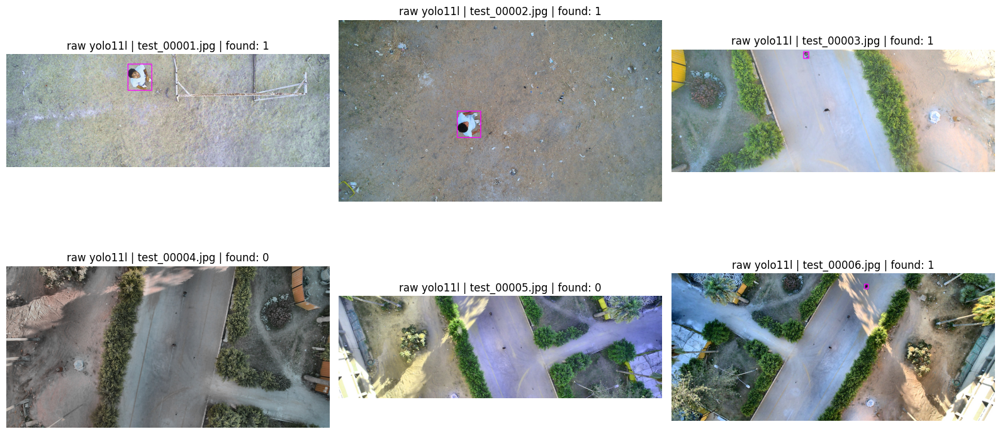

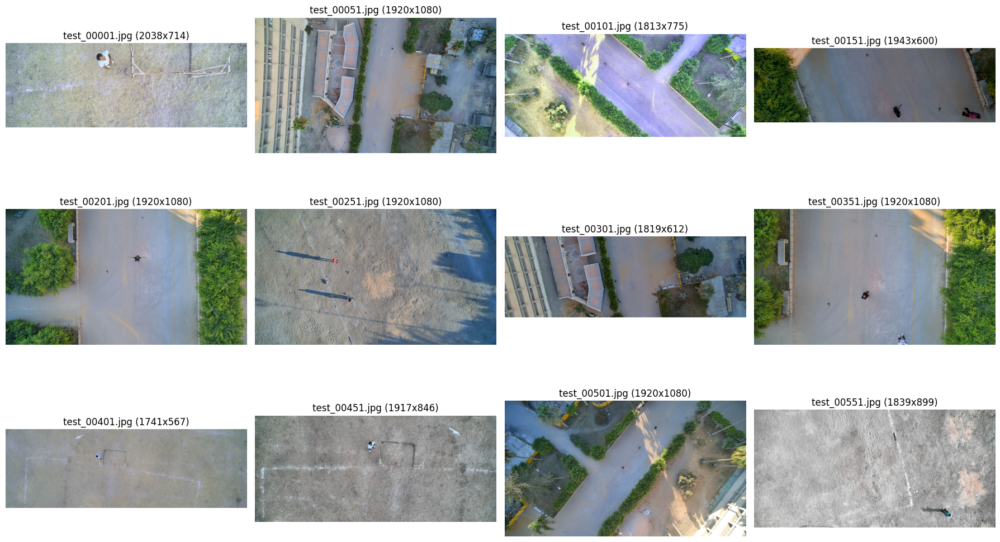

In [25]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

drive_dir = '/content/drive/MyDrive/drone_project'
test_dir = f'{drive_dir}/test_images'
all_test = sorted([f for f in os.listdir(test_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

raw_model = YOLO('yolo11l.pt')

first_six = all_test[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, fname in zip(axes.flatten(), first_six):
    img_path = os.path.join(test_dir, fname)
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H, W, _ = img.shape

    res = raw_model.predict(img_path, imgsz=1280, classes=[0], conf=0.15, verbose=False)[0]
    for box in res.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (255, 0, 255), 3)

    ax.imshow(img_rgb)
    ax.set_title(f"raw yolo11l | {fname} | found: {len(res.boxes)}")
    ax.axis('off')
plt.tight_layout()
plt.show()

step = len(all_test) // 12
spread_samples = [all_test[i * step] for i in range(12)]
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, fname in zip(axes.flatten(), spread_samples):
    img = cv2.imread(os.path.join(test_dir, fname))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H, W, _ = img.shape
    ax.imshow(img_rgb)
    ax.set_title(f"{fname} ({W}x{H})")
    ax.axis('off')
plt.tight_layout()
plt.show()

## Step 8: Multi-Model

YOLO11x + YOLO11l + YOLOv9c + YOLO11m

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


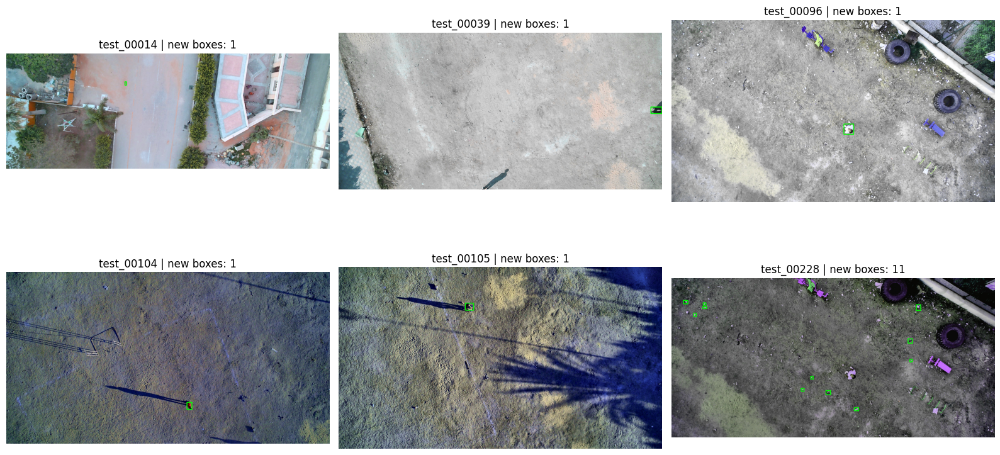

saved upgraded 5-token submission to: /content/drive/MyDrive/drone_project/submissions/submission_v2_5token.csv
total boxes exported: 1063 | avg per image: 1.8


In [27]:
import os
import cv2
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

drive_dir = '/content/drive/MyDrive/drone_project'
test_dir = f'{drive_dir}/test_images'
sample_sub_path = f'{drive_dir}/sample_submission.csv'
sub_out_v2 = f'{drive_dir}/submissions/submission_v2_5token.csv'

v9_model = YOLO(f'{drive_dir}/runs/drone_yolov9c_960/weights/best.pt')
v11_model = YOLO(f'{drive_dir}/runs/drone_yolo11m_960/weights/best.pt')
coco_l = YOLO('yolo11l.pt')
coco_x = YOLO('yolo11x.pt')

def apply_clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.2, tileGridSize=(8, 8))
    l = clahe.apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)

def boxes_overlap(b1, b2):
    ix1, iy1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    ix2, iy2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    a1 = (b1[2] - b1[0]) * (b1[3] - b1[1])
    a2 = (b2[2] - b2[0]) * (b2[3] - b2[1])
    return inter / (a1 + a2 - inter + 1e-6)

def clean_nadir_boxes(dets):
    if len(dets) <= 1:
        return dets
    dets = sorted(dets, key=lambda x: x[0], reverse=True)
    top_area = dets[0][3] * dets[0][4]
    kept = []
    for d in dets:
        c, xc, yc, w, h = d
        area = w * h
        if len(kept) > 0 and area < 0.14 * top_area:
            continue
        x1, y1, x2, y2 = xc - w / 2.0, yc - h / 2.0, xc + w / 2.0, yc + h / 2.0
        nested = False
        for kc, kxc, kyc, kw, kh in kept:
            kx1, ky1, kx2, ky2 = kxc - kw / 2.0, kyc - kh / 2.0, kxc + kw / 2.0, kyc + kh / 2.0
            ix1, iy1 = max(x1, kx1), max(y1, ky1)
            ix2, iy2 = min(x2, kx2), min(y2, ky2)
            inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
            iom = inter / (min(area, kw * kh) + 1e-6)
            if iom >= 0.45:
                nested = True
                break
        if not nested:
            kept.append(d)
    return kept

def detect_upgraded(img):
    H, W, _ = img.shape
    all_boxes = []
    all_scores = []

    img_180 = cv2.rotate(img, cv2.ROTATE_180)

    for m_coco, w_factor in [(coco_x, 1.0), (coco_l, 0.96)]:
        full_preds = m_coco.predict([img, img_180], imgsz=1280, classes=[0], conf=0.24, iou=0.45, verbose=False)
        for box in full_preds[0].boxes:
            c = float(box.conf[0].item()) * w_factor
            all_boxes.append(box.xyxyn[0].tolist())
            all_scores.append(c)
        for box in full_preds[1].boxes:
            c = float(box.conf[0].item()) * w_factor
            if c >= 0.28:
                fx1, fy1, fx2, fy2 = box.xyxyn[0].tolist()
                all_boxes.append([1.0 - fx2, 1.0 - fy2, 1.0 - fx1, 1.0 - fy1])
                all_scores.append(c * 0.95)

    windows = [
        (0, int(W * 0.48)),
        (int(W * 0.26), int(W * 0.74)),
        (int(W * 0.52), W)
    ]
    tiles_0 = [img[:, xs:xe] for xs, xe in windows]
    tiles_180 = [cv2.rotate(t, cv2.ROTATE_180) for t in tiles_0]

    for m_coco, w_factor in [(coco_x, 1.0), (coco_l, 0.95)]:
        tp_0 = m_coco.predict(tiles_0, imgsz=960, classes=[0], conf=0.25, iou=0.45, verbose=False)
        for (xs, xe), r_tile in zip(windows, tp_0):
            tw = xe - xs
            for box in r_tile.boxes:
                c = float(box.conf[0].item()) * w_factor
                tx1, ty1, tx2, ty2 = box.xyxy[0].tolist()
                if (xs > 0 and tx1 <= 4) or (xe < W and tx2 >= tw - 4):
                    continue
                all_boxes.append([max(0.0, min(1.0, (tx1 + xs) / W)), max(0.0, min(1.0, ty1 / H)),
                                  max(0.0, min(1.0, (tx2 + xs) / W)), max(0.0, min(1.0, ty2 / H))])
                all_scores.append(c)

        tp_180 = m_coco.predict(tiles_180, imgsz=960, classes=[0], conf=0.30, iou=0.45, verbose=False)
        for (xs, xe), r_tile in zip(windows, tp_180):
            tw = xe - xs
            for box in r_tile.boxes:
                c = float(box.conf[0].item()) * w_factor * 0.94
                fx1, fy1, fx2, fy2 = box.xyxy[0].tolist()
                tx1, ty1, tx2, ty2 = tw - fx2, H - fy2, tw - fx1, H - fy1
                if (xs > 0 and tx1 <= 4) or (xe < W and tx2 >= tw - 4):
                    continue
                all_boxes.append([max(0.0, min(1.0, (tx1 + xs) / W)), max(0.0, min(1.0, ty1 / H)),
                                  max(0.0, min(1.0, (tx2 + xs) / W)), max(0.0, min(1.0, ty2 / H))])
                all_scores.append(c)

    r_v9 = v9_model.predict(img, imgsz=1280, conf=0.30, iou=0.45, verbose=False)[0]
    r_v11 = v11_model.predict(img, imgsz=1280, conf=0.30, iou=0.45, verbose=False)[0]
    v11_boxes = [b.xyxyn[0].tolist() for b in r_v11.boxes]

    for box in r_v9.boxes:
        c = float(box.conf[0].item())
        b9 = box.xyxyn[0].tolist()
        agreed = any(boxes_overlap(b9, b11) >= 0.35 for b11 in v11_boxes) or any(boxes_overlap(b9, bc) >= 0.35 for bc in all_boxes)
        if c >= 0.48 or (c >= 0.32 and agreed):
            all_boxes.append(b9)
            all_scores.append(c * 0.92)

    top_so_far = max(all_scores) if all_scores else 0.0
    if top_so_far < 0.48 or img.mean() < 90:
        enh = apply_clahe(img)
        img_90 = cv2.rotate(enh, cv2.ROTATE_90_CLOCKWISE)
        img_270 = cv2.rotate(enh, cv2.ROTATE_90_COUNTERCLOCKWISE)
        rot_preds = coco_x.predict([enh, img_90, img_270], imgsz=1280, classes=[0], conf=0.22, iou=0.45, verbose=False)

        for box in rot_preds[0].boxes:
            all_boxes.append(box.xyxyn[0].tolist())
            all_scores.append(float(box.conf[0].item()) * 0.92)

        for box in rot_preds[1].boxes:
            u1, v1, u2, v2 = box.xyxyn[0].tolist()
            all_boxes.append([v1, 1.0 - u2, v2, 1.0 - u1])
            all_scores.append(float(box.conf[0].item()) * 0.90)

        for box in rot_preds[2].boxes:
            u1, v1, u2, v2 = box.xyxyn[0].tolist()
            all_boxes.append([1.0 - v2, u1, 1.0 - v1, u2])
            all_scores.append(float(box.conf[0].item()) * 0.90)

        tiles_enh = [enh[:, xs:xe] for xs, xe in windows]
        tp_v9 = v9_model.predict(tiles_enh, imgsz=960, conf=0.32, iou=0.45, verbose=False)
        for (xs, xe), r_tile in zip(windows, tp_v9):
            tw = xe - xs
            for box in r_tile.boxes:
                c = float(box.conf[0].item()) * 0.88
                tx1, ty1, tx2, ty2 = box.xyxy[0].tolist()
                if (xs > 0 and tx1 <= 4) or (xe < W and tx2 >= tw - 4):
                    continue
                all_boxes.append([max(0.0, min(1.0, (tx1 + xs) / W)), max(0.0, min(1.0, ty1 / H)),
                                  max(0.0, min(1.0, (tx2 + xs) / W)), max(0.0, min(1.0, ty2 / H))])
                all_scores.append(c)

    if not all_boxes:
        fb = coco_x.predict(img, imgsz=1280, classes=[0], conf=0.01, verbose=False)[0]
        if len(fb.boxes) > 0:
            b = fb.boxes[0]
            xc, yc, nw, nh = b.xywhn[0].tolist()
            return [(float(b.conf[0].item()), xc, yc, nw, nh)]
        return [(0.01, 0.5, 0.5, 0.02, 0.02)]

    b_tensor = torch.tensor(all_boxes, dtype=torch.float32)
    s_tensor = torch.tensor(all_scores, dtype=torch.float32)
    keep = torchvision.ops.nms(b_tensor, s_tensor, iou_threshold=0.40).tolist()

    final_dets = []
    for idx in keep:
        x1, y1, x2, y2 = all_boxes[idx]
        c = float(all_scores[idx])
        xc = max(0.0, min(1.0, (x1 + x2) / 2.0))
        yc = max(0.0, min(1.0, (y1 + y2) / 2.0))
        nw = max(0.0, min(1.0, x2 - x1))
        nh = max(0.0, min(1.0, y2 - y1))
        if nw > 0.002 and nh > 0.002:
            final_dets.append((c, xc, yc, nw, nh))

    final_dets.sort(key=lambda x: x[0], reverse=True)
    if len(final_dets) > 1:
        final_dets = [final_dets[0]] + [d for d in final_dets[1:] if d[0] >= 0.34]
    return clean_nadir_boxes(final_dets)

hard_ids = ['test_00014', 'test_00039', 'test_00096', 'test_00104', 'test_00105', 'test_00228']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, img_id in zip(axes.flatten(), hard_ids):
    img = cv2.imread(os.path.join(test_dir, img_id + '.jpg'))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H, W, _ = img.shape
    dets = detect_upgraded(img)
    for c, xc, yc, nw, nh in dets:
        x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
        x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
        cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), 3)
    ax.imshow(img_rgb)
    ax.set_title(f"{img_id} | new boxes: {len(dets)}")
    ax.axis('off')
plt.tight_layout()
plt.show()

sample_df = pd.read_csv(sample_sub_path, dtype=str, keep_default_na=False)
target_ids = sample_df['image_id'].tolist()

rows_v2 = []
total_boxes = 0

for img_id in target_ids:
    img_path = os.path.join(test_dir, img_id + '.jpg')
    img = cv2.imread(img_path)
    H, W, _ = img.shape
    is_rot_crop = (W, H) != (1920, 1080)
    dets = detect_upgraded(img)
    total_boxes += len(dets)

    boxes_5 = []
    for c, xc, yc, w, h in dets:
        is_dummy = (abs(xc - 0.5) < 1e-4 and abs(yc - 0.5) < 1e-4 and abs(w - 0.02) < 1e-4)
        if is_rot_crop and not is_dummy:
            w = min(1.0, w * 1.28)
            h = min(1.0, h * 1.35)
        elif not is_dummy:
            w = min(1.0, w * 1.12)
            h = min(1.0, h * 1.12)
        boxes_5.append(f"1 {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}")

    rows_v2.append({'image_id': img_id, 'PredictionString': " ".join(boxes_5)})

pd.DataFrame(rows_v2).to_csv(sub_out_v2, index=False)
print("saved upgraded 5-token submission to:", sub_out_v2)
print("total boxes exported:", total_boxes, "| avg per image:", round(total_boxes / len(rows_v2), 2))